# Overfitting and Regularization: The Math Behind Models That Generalize
### Why models fail and how linear algebra, calculus and probability help us fix them

**Author:** Eleonora Kuteva

**Course:** Math Concepts for Developers - Final Project

## Abstract
> TODO (write last): 4-5 sentences. What is the problem, what did you do, what did you find.

## Table of Contents
1. Introduction
2. Setup
3. Data
4. Linear Regression from Scratch
5. Polynomial Regression
6. Overfitting and Underfitting
7. The Bias-Variance Tradeoff
8. Regularization: Ridge and Lasso
9. Model Selection with Cross-Validation
10. Real-World Application
11. Discussion and Limitations
12. Conclusion and Next Steps
13. References

## 1. Introduction

### 1.1. Problem formulation

The goal of a machine learning model is not to describe the data it was trained on, but to make accurate predictions on data it has never seen. This ability is called **generalization**. A model can reach almost zero error on its training set and still perform poorly on new inputs, so a low training error alone says very little about how useful a model really is.

A model can fail to generalize in two opposite ways:

- **Overfitting:** the model is too flexible for the amount of data available. Instead of learning only the underlying relationship, it also fits the random noise in the training samples. As a result, the training error is very low, but the error on new data is high. Typical causes are an overly complex model, noisy data and outliers [1].
- **Underfitting:** the model is too simple to capture the true relationship. It makes large errors on both the training data and new data.

A simple example illustrates the problem. If we fit a polynomial of degree 15 to 20 noisy points, the curve can pass through almost every point, but between them it oscillates wildly and has little in common with the true function. A straight line, on the other hand, misses the shape of the data completely. A good model lies somewhere between these two extremes.

This project addresses the following question: **how can we choose the complexity of a model so that its error on unseen data is as small as possible, and how can we detect and prevent overfitting?**

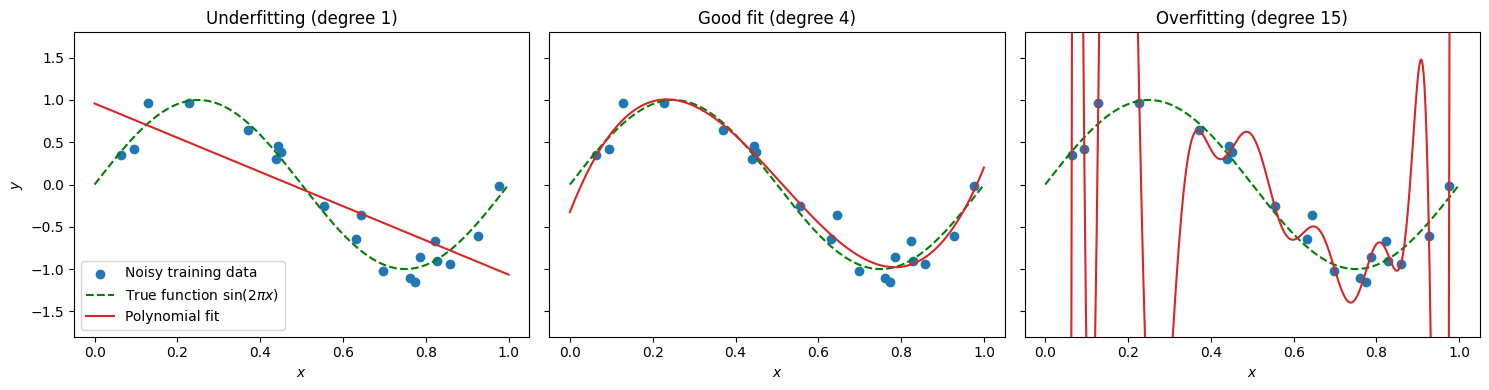

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Illustration only: the full experiment is in Section 6
rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 1, 20))
y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, x.size)
x_plot = np.linspace(0, 1, 500)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
titles = ["Underfitting (degree 1)", "Good fit (degree 4)", "Overfitting (degree 15)"]

for ax, degree, title in zip(axes, [1, 4, 15], titles):
    model = np.polynomial.Polynomial.fit(x, y, degree)
    ax.scatter(x, y, color="tab:blue", label="Noisy training data")
    ax.plot(x_plot, np.sin(2 * np.pi * x_plot), "g--", label=r"True function $\sin(2\pi x)$")
    ax.plot(x_plot, model(x_plot), color="tab:red", label="Polynomial fit")
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.set_ylim(-1.8, 1.8)

axes[0].set_ylabel("$y$")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Figure 1: Underfitting, good fit and overfitting.** The degree 1 model is too simple: the straight line misses both the peak and the trough of the true function. The degree 4 model follows the true function closely. The degree 15 model passes very close to the training points, but between them it oscillates far away from the true function, so its predictions for new points would be poor.

### 1.2. Why is this important?

Every supervised learning model is trained on a finite sample and is later used on data outside that sample. Overfitting is therefore not a rare special case, but a risk that every model faces. Some examples of where it matters:

- **Medical diagnosis:** a model trained on patients from a single hospital may learn patterns that are specific to that dataset and perform worse on patients from other hospitals.
- **Price prediction:** a model for house prices may memorize the particular houses in its training set and give unreliable estimates for new properties.
- **Finance:** a trading strategy tuned too closely to historical data may look excellent on past data and fail on future data.

### 1.3. Objectives and scope

The objectives of this project are to:

1. Implement linear regression from scratch using the normal equation and justify the mean squared error loss through maximum likelihood (Section 4).
2. Use polynomial regression to demonstrate underfitting and overfitting by comparing training and test error for different polynomial degrees (Sections 5 and 6).
3. Derive the bias-variance decomposition of the expected error and confirm it with a simulation (Section 7).
4. Derive and implement Ridge (L2) regularization, explain Lasso (L1) regularization mathematically and geometrically, and study the effect of the regularization strength $\lambda$ (Section 8).
5. Implement k-fold cross-validation from scratch and use it to select the polynomial degree and $\lambda$ (Section 9).
6. Apply these methods to a real-world dataset, the diabetes dataset [3] (Section 10).

All methods implemented from scratch are verified against the corresponding implementations in scikit-learn [2].

**Out of scope:** the project focuses only on regression with a squared error loss. Classification, neural networks and deep learning, as well as other regularization techniques such as dropout, early stopping and data augmentation, are not covered.

### 1.4. Assumptions

- **Data-generating process:** the data is generated as $y = f(x) + \varepsilon$, where $f$ is an unknown function and $\varepsilon$ is random noise. With synthetic data, $f$ is known, so we can compare every model with the true answer.
- **Independent and identically distributed (i.i.d.) samples:** all training and test points come independently from the same distribution. Without this assumption, the test error would not be a fair estimate of the error on future data.
- **Gaussian noise with zero mean:** $\varepsilon \sim \mathcal{N}(0, \sigma^2)$. This assumption is what connects maximum likelihood to the mean squared error (Section 4.3), and $\sigma^2$ appears as the irreducible error in the bias-variance decomposition (Section 7).
- **Polynomial approximation:** the true function can be approximated well by a polynomial of moderate degree. This justifies the use of polynomial regression in Section 5.
- **Real-world data:** for the diabetes dataset, we assume that a linear model of the features is a reasonable approximation of the target.



## 2. Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures


RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 3. Data

### 3.1. Synthetic data
We generate data from a known function and add noise, so we know the "true" answer:
$$ y = f(x) + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2) $$


We choose the true function $f(x) = \sin(2\pi x)$ on the interval $[0, 1]$, generate 30 points and add Gaussian noise with $\sigma = 0.2$.

**Why synthetic data?** We use synthetic data because we know the exact formula behind it. This is important because we can compare every model with the true function and evaluate it properly. With real data, the true function is unknown.

**Why $\sin(2\pi x)$?** The sine function has peaks and troughs, and that is why a straight line cannot describe it well. If the true function were a straight line, we could not show underfitting, because even the simplest model would describe it well. With the sine function, we can show both underfitting and overfitting. The sine is also not a polynomial, and this is important: the polynomial models we will use later can only be a close approximation of the true function, but never exactly equal to it. This is also the situation with real data, where every model is only an approximation.

**Why 30 points?** Overfitting depends on the ratio between the amount of data and the complexity of the model, so a small number of points is necessary to show overfitting. With many points, even a complex model cannot memorize all of them and is forced to follow the true function.

**Why $\sigma = 0.2$?** If $\sigma = 0$, there is no noise, so there is nothing for the model to memorize by mistake and overfitting cannot be shown. If $\sigma = 1$, the noise is as large as the sine itself and its shape is lost in the noise. With $\sigma = 0.2$, the shape of the sine is clearly visible, but there is enough noise for a complex model to overfit.


In [3]:
def true_function(x):
    """
    The true function f(x) = sin(2*pi*x) that generates the data.
    """
    return np.sin(2 * np.pi * x)

def generate_data(num_points, noise_std, x_min = 0, x_max = 1):
    """
    Generates num_points noisy samples of the true function in the range [x_min; x_max].
    Returns the arrays x and y
    """
    x = np.sort(np.random.uniform(x_min, x_max, num_points))
    noise = np.random.normal(0, noise_std, num_points)
    y = true_function(x) + noise
    return x, y

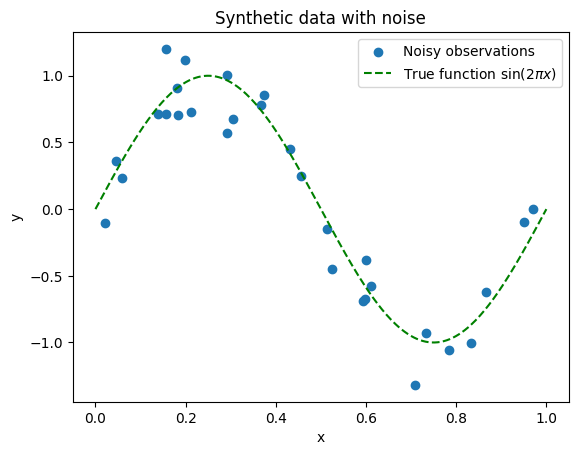

In [4]:
NUM_POINTS = 30
NOISE_STD = 0.2

x, y = generate_data(NUM_POINTS, NOISE_STD)
x_plot = np.linspace(0, 1, 300)
plt.scatter(x, y, color="tab:blue", label="Noisy observations")
plt.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
plt.title("Synthetic data with noise")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Figure 2: Synthetic data with noise.** The noisy observations clearly follow the shape of the true function: they rise to a peak around $x = 0.25$ and fall to a trough around $x = 0.75$. Because of the noise, the points do not lie exactly on the curve, but all of them stay within about $0.4$ of it, so the underlying sine is easy to recognize.

### 3.2. Train / test split

If we test the model on the same data that it learned from, we cannot tell whether it has learned the true pattern or has just memorized the points. For this purpose, we evaluate it on new points that it has not seen. This is the test set. The points are chosen randomly, so that both the training and the test points are spread over the whole interval. Otherwise, the model would never see part of the curve.

In [5]:
def train_test_split(x, y, test_ratio = 0.3):
    """
    Randomly splits the data into a training set and a test set.
    Returns x_train, x_test, y_train, y_test
    """
    if len(x) != len(y):
        raise ValueError("x and y must have the same length")
    indices = np.random.permutation(len(x))
    test_size = int(len(x) * test_ratio)
    test_indices = indices[:test_size]
    train_indices = indices[test_size:]

    return x[train_indices], x[test_indices], y[train_indices], y[test_indices]
    

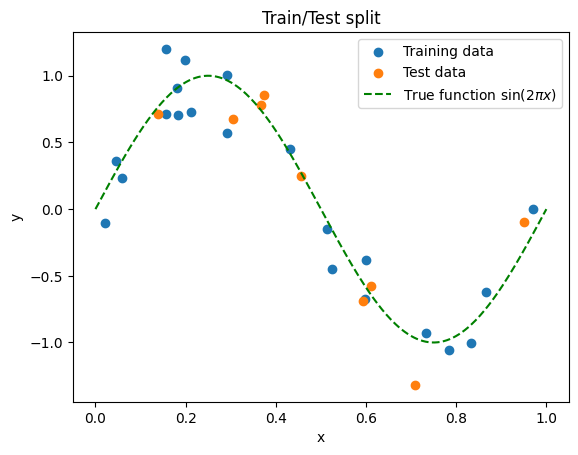

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y)

plt.scatter(x_train, y_train, color="tab:blue", label="Training data")
plt.scatter(x_test, y_test, color="tab:orange", label="Test data")
plt.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
plt.title("Train/Test split")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Figure 3: Train / test split.** The 30 points are randomly divided into 21 training points (blue) and 9 test points (orange). The test points are spread over the whole interval and include points near both the peak and the trough of the sine. This means that the test set checks the model on every part of the curve, not only on one region.

## 4. Linear Regression from Scratch

### 4.1. The model and the loss function
$$ \hat{\mathbf{y}} = X\mathbf{w}, \qquad L(\mathbf{w}) = \frac{1}{n}\lVert \mathbf{y} - X\mathbf{w} \rVert^2 $$

**The model.** $X$ is the design matrix with $n$ rows and 2 columns, where each row is one training point: the first column contains only ones and the second column contains the $x$ values (in our case $n = 21$). $\mathbf{w} = [w_0, w_1]$ is the weight vector, where $w_0$ is the intercept (the value of $\hat{y}$ when $x = 0$) and $w_1$ is the slope (how much $\hat{y}$ changes when $x$ increases by 1). The column of ones makes the intercept part of the matrix product, because each row gives $1 \cdot w_0 + x_i \cdot w_1$. Without it, the line would always pass through the origin $(0, 0)$. The result $\hat{\mathbf{y}}$ is a vector of $n$ predictions, one for each training point. The matrix form computes all of them in one operation, and the same code works for any number of columns, so we will reuse it for polynomial regression in Section 5.

**The loss.** $\mathbf{y} - X\mathbf{w}$ is the vector of residuals, the vertical distances $y_i - \hat{y}_i$ between each data point and the line. $\lVert \cdot \rVert^2$ squares every residual and sums them, and the factor $\frac{1}{n}$ turns this sum into an average, so the loss does not depend on the number of points and train and test errors can be compared. Squaring prevents positive and negative errors from cancelling out, penalizes large errors more than small ones and makes $L(\mathbf{w})$ a smooth function of $\mathbf{w}$, which we will differentiate in Section 4.2. This loss is exactly what our `mean_squared_error` function computes.

### 4.2. Deriving the normal equation

We want the weights $\mathbf{w}$ that make the loss $L(\mathbf{w})$ as small as possible. At the minimum of a smooth function the slope is zero in every direction, so all partial derivatives must be zero at the same time. Together they form the gradient $\nabla L(\mathbf{w})$, and the condition for the minimum is $\nabla L(\mathbf{w}) = \mathbf{0}$.

**Step 1: expand the loss.** Using $\lVert \mathbf{v} \rVert^2 = \mathbf{v}^T\mathbf{v}$ and the rule $(X\mathbf{w})^T = \mathbf{w}^TX^T$, we expand the loss in the same way as $(a - b)^2 = a^2 - 2ab + b^2$:

$$ L(\mathbf{w}) = \frac{1}{n}(\mathbf{y} - X\mathbf{w})^T(\mathbf{y} - X\mathbf{w}) = \frac{1}{n}\Big(\mathbf{y}^T\mathbf{y} - 2\,\mathbf{w}^TX^T\mathbf{y} + \mathbf{w}^TX^TX\mathbf{w}\Big) $$

The two middle terms $\mathbf{y}^TX\mathbf{w}$ and $\mathbf{w}^TX^T\mathbf{y}$ are the same number, which is why they combine into $2\,\mathbf{w}^TX^T\mathbf{y}$.

**Step 2: take the gradient.** The first term $\mathbf{y}^T\mathbf{y}$ does not depend on $\mathbf{w}$, so its derivative is zero. For the other two terms we use the vector versions of the rules $(cw)' = c$ and $(kw^2)' = 2kw$ [4, 5]:

$$ \nabla_{\mathbf{w}}\big(\mathbf{w}^TX^T\mathbf{y}\big) = X^T\mathbf{y}, \qquad \nabla_{\mathbf{w}}\big(\mathbf{w}^TX^TX\mathbf{w}\big) = 2X^TX\mathbf{w} $$

$$ \nabla L(\mathbf{w}) = \frac{1}{n}\Big(-2X^T\mathbf{y} + 2X^TX\mathbf{w}\Big) $$

**Step 3: set the gradient to zero.** Multiplying by $\frac{n}{2}$ and moving the term with $\mathbf{y}$ to the right side gives the **normal equation**:

$$ X^TX\mathbf{w} = X^T\mathbf{y} \qquad \Longrightarrow \qquad \mathbf{w} = (X^TX)^{-1}X^T\mathbf{y} $$

The second form is valid only when $X^TX$ is invertible. The loss is a quadratic "bowl" that opens upwards, so this point is a minimum and not a maximum. In `fit_linear_regression` we solve the normal equation with `np.linalg.solve` instead of computing the inverse matrix, because it is faster and numerically more stable. The derivation also does not depend on the number of columns of $X$, so the same function will work for polynomial regression in Section 5.

### 4.3. Probabilistic view (Maximum Likelihood)

The mean squared error is not an arbitrary choice: it follows from the assumption of Gaussian noise in Section 1.4 [4]. Our model says that $y_i = \mathbf{x}_i^T\mathbf{w} + \varepsilon_i$ with $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$, where $\mathbf{x}_i^T$ is the $i$-th row of $X$. This means that each observed $y_i$ is spread around the prediction $\hat{y}_i = \mathbf{x}_i^T\mathbf{w}$ like a bell curve with width $\sigma$:

$$ p(y_i \mid \mathbf{x}_i, \mathbf{w}) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(y_i - \hat{y}_i)^2}{2\sigma^2}\right) $$

Points close to the line have a high probability, and points far from it have a very low probability. Because the samples are i.i.d., the probability of observing the whole dataset, called the **likelihood**, is the product of the individual probabilities:

$$ p(\mathbf{y} \mid X, \mathbf{w}) = \prod_{i=1}^{n} p(y_i \mid \mathbf{x}_i, \mathbf{w}) $$

The logarithm turns the product into a sum and does not change the location of the maximum, because it is an increasing function:

$$ \log p(\mathbf{y} \mid X, \mathbf{w}) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 $$

The first term and the factor $\frac{1}{2\sigma^2}$ do not depend on $\mathbf{w}$. Because of the minus sign, the log-likelihood is largest when the sum of squared residuals is smallest, and this sum is $n$ times the MSE. Therefore, **maximizing the likelihood is the same as minimizing the MSE**, and the maximum likelihood weights are exactly the solution of the normal equation from Section 4.2. If the noise were not Gaussian (for example, with many large outliers), this argument would lead to a different loss function.

In [7]:
def fit_linear_regression(X, y):
    """
    Finds the weights using the normal equation
    """
    xtx = X.T @ X
    xty = X.T @ y
    return np.linalg.solve(xtx, xty)


def predict(X, w):
    """
    Returns the predictions of the model
    """
    return X @ w


def mean_squared_error(y_true, y_pred):
    """
    Calculates the mean squared error
    """
    return np.mean((y_true - y_pred) ** 2)

In [8]:
# design matrices
X_train = np.column_stack([np.ones(len(x_train)), x_train])
X_test = np.column_stack([np.ones(len(x_test)), x_test])

# fit on the TRAINING data
w = fit_linear_regression(X_train, y_train)

# Make predictions
y_train_pred = predict(X_train, w)
y_test_pred = predict(X_test, w)

# Calculate errors
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print("Weights: w0 =", w[0], ", w1 =", w[1])
print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

Weights: w0 = 0.8744533525105839 , w1 = -1.818388225813362
Train MSE: 0.2246188774485666
Test MSE: 0.2992132241021882


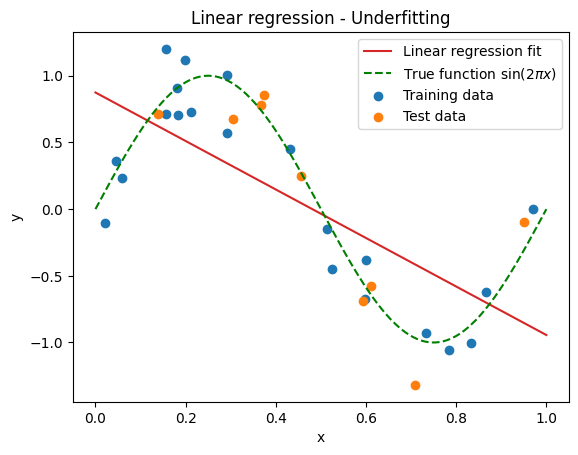

In [9]:
x_plot_design = np.column_stack([np.ones(len(x_plot)), x_plot])
y_plot_pred = predict(x_plot_design, w)
plt.plot(x_plot, y_plot_pred, color="tab:red", label="Linear regression fit")
plt.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
plt.scatter(x_train, y_train, color="tab:blue", label="Training data")
plt.scatter(x_test, y_test, color="tab:orange", label="Test data")
plt.title("Linear regression - Underfitting")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Figure 4: Linear regression fit.** The figure shows the best straight line through the training data. The line goes down from left to right and misses both the peak and the trough of the sine, on the training points as well as on the test points. The MSE on both the training set (0.225) and the test set (0.299) is more than 5 times larger than the noise level $\sigma^2 = 0.04$, so the model has not learned the shape of the data. The two errors are close to each other, which means that the model has not memorized the training data either. This is a typical example of **underfitting**: a straight line is too simple to describe the sine.

### 4.4. Validation against scikit-learn

We compared the weights from our implementation of the normal equation with scikit-learn's `LinearRegression`, fitted on the same design matrix `X_train` (with `fit_intercept=False`, because `X_train` already contains the column of ones). The two sets of weights are identical up to rounding errors (`np.allclose` returns `True`). This confirms that our implementation of the normal equation is correct.

In [10]:
# Fit scikit-learn's model on the same design matrix X_train.
# fit_intercept=False because X_train already contains the column of ones.
sk_model = LinearRegression(fit_intercept=False)
sk_model.fit(X_train, y_train)

# Compare the weights
print("Our weights:     ", w)
print("sklearn weights: ", sk_model.coef_)

# np.allclose checks if two arrays are equal up to tiny rounding errors
print("Same weights?", np.allclose(w, sk_model.coef_))

Our weights:      [ 0.87445335 -1.81838823]
sklearn weights:  [ 0.87445335 -1.81838823]
Same weights? True


## 5. Polynomial Regression

A straight line cannot describe the sine, so we give the model more flexibility by adding powers of $x$:

$$ \hat{y} = w_0 + w_1x + w_2x^2 + \dots + w_dx^d $$

where $d$ is the degree of the polynomial. The curve is not a straight line in $x$, but the model is still **linear in the weights** [4]. The values of $x$ come from the data, so for a given point $x, x^2, \dots, x^d$ are just known numbers. For example, for $x = 0.5$ the model becomes $\hat{y} = w_0 + 0.5\,w_1 + 0.25\,w_2 + \dots$: every weight appears only to the first power and is multiplied by a known number. The derivation of the normal equation in Section 4.2 only uses the fact that $\hat{\mathbf{y}} = X\mathbf{w}$, so it is still valid.

### 5.1. The design (Vandermonde) matrix

The only thing that changes is the design matrix. Each row is one data point and each column is one power of $x$, from $x^0 = 1$ to $x^d$, so the matrix has $d + 1$ columns. This matrix is called the **Vandermonde matrix**:

$$ X = \begin{bmatrix} 1 & x_1 & x_1^2 & \dots & x_1^d \\ 1 & x_2 & x_2^2 & \dots & x_2^d \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ 1 & x_n & x_n^2 & \dots & x_n^d \end{bmatrix} $$

The design matrix from Section 4 is the special case $d = 1$, with the columns $[1, x]$. Therefore `fit_linear_regression` and `predict` can be reused without any change; we only need a new function that builds $X$.

Higher powers of $x$ create a numerical problem. All our $x$ values are between 0 and 1, so the high powers become very small: for example, $0.5^{15} \approx 0.00003$. To have a visible effect on the prediction, the weight in front of such a column must be very large. In addition, the columns $x^{14}$ and $x^{15}$ are almost the same, so the model can give them very large weights with opposite signs that almost cancel at the training points but not between them. We will measure this effect in Section 6, and it is the main motivation for regularization in Section 8.

In [11]:
def polynomial_features(x, degree):
    """
    Returns the matrix [1, x, x^2, ..., x^degree]
    """
    return np.column_stack([x ** k for k in range(degree + 1)])


In [12]:
# sklearn expects x as a column (2D array)
x_train_column = x_train.reshape(-1, 1)
sk_poly = PolynomialFeatures(degree=3).fit_transform(x_train_column)

print("Same matrix as sklearn?", np.allclose(polynomial_features(x_train, 3), sk_poly))

Same matrix as sklearn? True


### 5.2. Fitting polynomials of different degrees

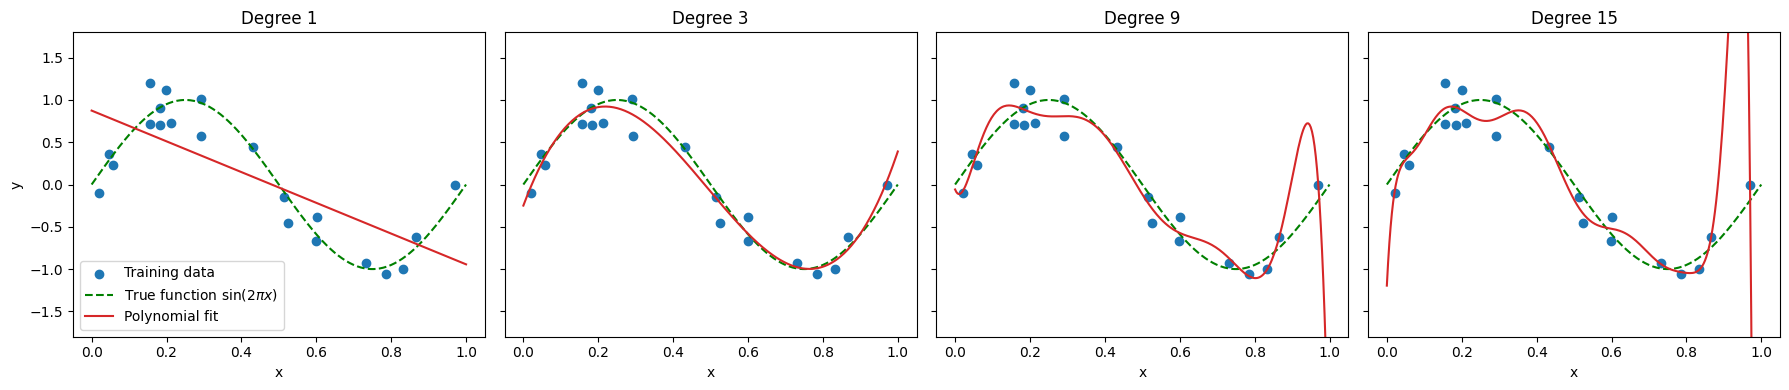

In [13]:
degrees = [1, 3, 9, 15]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

for ax, degree in zip(axes, degrees):
    # 1. Build the design matrices
    X_train_poly = polynomial_features(x_train, degree)
    X_plot_poly = polynomial_features(x_plot, degree)

    # 2. Fit on the training data and predict on the smooth x_plot
    w_poly = fit_linear_regression(X_train_poly, y_train)
    y_plot_poly = predict(X_plot_poly, w_poly)

    # 3. Plot
    ax.scatter(x_train, y_train, color="tab:blue", label="Training data")
    ax.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
    ax.plot(x_plot, y_plot_poly, color="tab:red", label="Polynomial fit")
    ax.set_title(f"Degree {degree}")
    ax.set_xlabel("x")
    ax.set_ylim(-1.8, 1.8)

axes[0].set_ylabel("y")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Figure 5: Polynomial fits of degree 1, 3, 9 and 15.** All four models are fitted with the same `fit_linear_regression` function; only the number of columns in the design matrix changes. 
- The degree 1 model is a straight line and underfits, as in Section 4. 
- The degree 3 model follows the true function $\sin(2\pi x)$ closely over the whole interval. 
- The degree 9 model starts to bend between the training points in order to pass closer to them, which means that it begins to fit the noise, and it drops sharply near $x = 1$. 
- The degree 15 model passes very close to almost every training point, but it oscillates strongly near the edges of the interval and leaves the plotted range (the $y$-axis is limited to $[-1.8, 1.8]$ for readability). The largest deviations appear where there is no training data, for example between $x \approx 0.87$ and $x \approx 0.97$, and this is exactly where new points can appear. This is overfitting: the model fits the training data very well but does not describe the true function. 

In Section 6 we measure this effect with the training and test errors.

## 6. Overfitting and Underfitting

In Section 5 we saw overfitting visually. In this section we measure it with numbers: for every degree from 1 to 15 we fit the model on the training data and compute the training and test errors (Section 6.1). Then we look at the size of the fitted weights (Section 6.2).

### 6.1. Train and test error

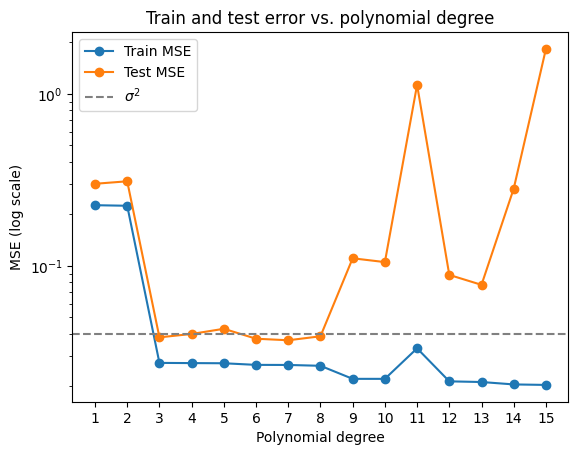

In [14]:
degrees = range(1, 16)
train_errors = []
test_errors = []

for degree in degrees:
    # Build the design matrices for train and test
    X_train_poly = polynomial_features(x_train, degree)
    X_test_poly = polynomial_features(x_test, degree)

    # Fit on the training data only
    w_poly = fit_linear_regression(X_train_poly, y_train)

    # Compute the errors and save them
    train_errors.append(mean_squared_error(y_train, predict(X_train_poly, w_poly)))
    test_errors.append(mean_squared_error(y_test, predict(X_test_poly, w_poly)))

plt.semilogy(degrees, train_errors, "o-", color="tab:blue", label="Train MSE")
plt.semilogy(degrees, test_errors, "o-", color="tab:orange", label="Test MSE")
plt.axhline(NOISE_STD ** 2, color="gray", linestyle="--", label=r"$\sigma^2$")
plt.title("Train and test error vs. polynomial degree")
plt.xlabel("Polynomial degree")
plt.xticks(degrees)
plt.ylabel("MSE (log scale)")
plt.legend()
plt.show()

**Figure 6: Train and test error as a function of the polynomial degree.** The $y$-axis uses a logarithmic scale because the test error of the most complex models is many times larger than the others. The dashed line is the noise level $\sigma^2 = 0.04$, which no model can beat on new data.

- **Degrees 1–2 (underfitting):** both errors are high (around 0.3), because the model is too simple to describe the sine.
- **Degrees 3–8 (good fit):** the test error drops to about 0.04, the level of the noise. The lowest test error (0.037) is at degree 7, but all models in this range are almost equally good, so the simpler degree 3 is a reasonable choice.
- **Degrees 9–15 (overfitting):** the training error continues to decrease, but the test error grows and reaches 1.82 at degree 15, about 50 times more than the best model.

The training error is always below $\sigma^2$ from degree 3 onwards, because the model starts to fit part of the noise in the training data. Therefore, the training error alone cannot be used to choose the degree: it always prefers the most complex model. The test error forms the typical **U-shaped curve**. Its right side is not smooth, because the test set contains only 9 points, and a single point in a region without training data (for example $x \approx 0.95$) can change the error a lot.

The small increase of the training error at degree 11 is not expected from the theory, because a higher-degree model can always reproduce a lower-degree one by setting the extra weights to zero. It is a numerical effect: for high degrees the columns of the Vandermonde matrix are almost identical, $X^TX$ is very close to a singular matrix, and `np.linalg.solve` loses precision. Ridge regression in Section 8 solves this problem.


### 6.2. Size of the weights

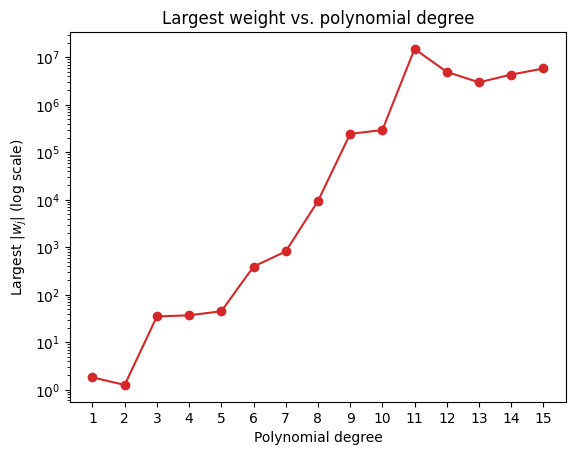

In [15]:
max_weights = []

for degree in degrees:
    X_train_poly = polynomial_features(x_train, degree)
    w_poly = fit_linear_regression(X_train_poly, y_train)

    # the largest absolute value among the weights
    max_weights.append(np.max(np.abs(w_poly)))

plt.semilogy(degrees, max_weights, "o-", color="tab:red")
plt.title("Largest weight vs. polynomial degree")
plt.xlabel("Polynomial degree")
plt.xticks(degrees)
plt.ylabel(r"Largest $|w_j|$ (log scale)")
plt.show()

**Figure 7: The largest absolute weight as a function of the polynomial degree.** The $y$-axis uses a logarithmic scale. For degrees 1–5 the largest weight is below 50, but from degree 6 it grows very fast and reaches about $1.5 \cdot 10^7$ at degree 11, about seven orders of magnitude more than for the straight line. The weights start to explode at degrees 8–9, the same degrees where the test error in Figure 6 starts to grow. As explained in Section 5.1, the high powers of $x$ are very small and almost identical, so the model uses very large weights with opposite signs that cancel at the training points. Between the training points this cancellation is not exact, and a small change in $x$ leads to a large change in $\hat{y}$, which is why the curve oscillates. This suggests a natural solution to overfitting: **penalize large weights**. This is the idea of regularization in Section 8.

## 7. The Bias-Variance Tradeoff

Section 6 showed *what* happens when the degree grows: the training error keeps falling, while the test error first falls and then rises. This section explains *why*. We split the expected error on a new point into three parts: bias, variance and noise [6], [7].

### 7.1. Derivation

**Setup.** Let $x_0$ be a new point that was not used for training, with true value $y_0 = f(x_0) + \varepsilon$, where $\mathbb{E}[\varepsilon] = 0$ and $\text{Var}(\varepsilon) = \sigma^2$. The model $\hat{f}$ is learned from a training dataset $D$. Because $D$ contains random noise, $\hat{f}$ is random too: a different training set would give a different model and a different prediction $\hat{f}(x_0)$. The **average model** is the prediction we would get on average over many training sets:

$$ \bar{f}(x_0) = \mathbb{E}_D\left[\hat{f}(x_0)\right] $$

There are two independent sources of randomness: the training data $D$, which determines $\hat{f}$, and the noise $\varepsilon$ at the new point. The expectation $\mathbb{E}$ below is taken over both. To keep the notation short, we write $f$, $\hat{f}$ and $\bar{f}$ for $f(x_0)$, $\hat{f}(x_0)$ and $\bar{f}(x_0)$.

**Step 1: add and subtract.** Adding and subtracting $\bar{f}$ does not change the error, but it splits it into three parts:

$$ y_0 - \hat{f} = f + \varepsilon - \hat{f} = \underbrace{(f - \bar{f})}_{A} + \underbrace{(\bar{f} - \hat{f})}_{B} + \underbrace{\varepsilon}_{C} $$

- $A = f - \bar{f}$ is a constant: it is the distance between the average model and the truth, and it does not depend on $D$.
- $B = \bar{f} - \hat{f}$ is how far this particular model is from the average model. It depends on $D$, and its mean is zero: $\mathbb{E}[B] = \bar{f} - \mathbb{E}[\hat{f}] = \bar{f} - \bar{f} = 0$.
- $C = \varepsilon$ is the noise at the new point, with $\mathbb{E}[C] = 0$.

**Step 2: square.** Using $(a + b + c)^2 = a^2 + b^2 + c^2 + 2ab + 2ac + 2bc$:

$$ (y_0 - \hat{f})^2 = A^2 + B^2 + C^2 + 2AB + 2AC + 2BC $$

**Step 3: take the expectation.** The expectation of a sum is the sum of the expectations, so we look at each term separately:

- $\mathbb{E}[A^2] = (\bar{f} - f)^2$, because $A$ is a constant. This is the **squared bias**.
- $\mathbb{E}[B^2] = \mathbb{E}_D\left[(\hat{f} - \bar{f})^2\right]$, the average squared distance of a model from its own mean. This is the **variance**.
- $\mathbb{E}[C^2] = \mathbb{E}[\varepsilon^2] = \sigma^2$, the **noise variance**.
- $\mathbb{E}[2AB] = 2A\,\mathbb{E}[B] = 0$, because $A$ is a constant and $\mathbb{E}[B] = 0$.
- $\mathbb{E}[2AC] = 2A\,\mathbb{E}[\varepsilon] = 0$, because the noise has zero mean.
- $\mathbb{E}[2BC] = 2\,\mathbb{E}[B]\,\mathbb{E}[\varepsilon] = 0$, because $B$ depends only on the noise in the training points, while $\varepsilon$ is the noise at the new point. By the i.i.d. assumption from Section 1.4, the two are independent, so the expectation of their product is the product of their expectations.

All three cross terms vanish, and we get the **bias-variance decomposition**:

$$ \mathbb{E}\left[(y_0 - \hat{f}(x_0))^2\right] = \underbrace{\left(\bar{f}(x_0) - f(x_0)\right)^2}_{\text{Bias}^2} + \underbrace{\mathbb{E}_D\left[\left(\hat{f}(x_0) - \bar{f}(x_0)\right)^2\right]}_{\text{Variance}} + \underbrace{\sigma^2}_{\text{Noise}} $$

**What each term means:**

- **Bias²** measures how wrong the model is *on average*. It is large when the model is too simple to follow the true function, for example a straight line fitted to a sine. This is underfitting.
- **Variance** measures how much the model changes when the training data changes. It is large when the model is flexible enough to follow the noise, for example a polynomial of degree 15 fitted to 21 points. This is overfitting.
- **Noise $\sigma^2$** is the irreducible error. It comes from the data, not from the model, so no model can reduce it. This is why no model in Figure 6 has a test error far below $\sigma^2 = 0.04$.

A more complex model usually has lower bias but higher variance. The best degree is the one that balances the two, which is what the U-shaped test error in Figure 6 shows. Bias and variance cannot be measured from a single dataset, because both are defined as averages over many training sets. In Section 7.2, we therefore estimate them with a simulation.

### 7.2. Simulation

To estimate the bias and the variance, we repeat the training many times on new data. We keep the 21 training inputs `x_train` fixed and generate 200 new training sets by adding new noise to the true function, $y = f(x) + \varepsilon$. Only the noise changes between the datasets, so the differences between the fitted models come from the noise alone, which is exactly how the variance is defined. Keeping the inputs fixed also avoids an almost singular $X^TX$ at high degrees. For every degree from 1 to 15, we fit a model on each dataset and predict on the 300 points of `x_plot`. The average of the 200 predictions is our estimate of the average model $\bar{f}$. From it, we compute the squared bias and the variance as in Section 7.1, averaged over all points of `x_plot`.

In [16]:
rng = np.random.default_rng(0)
NUM_DATASETS = 200
degrees = range(1, 16)
true_values = true_function(x_plot)

bias_squared_list = []
variance_list = []

for degree in degrees:
    # 1. Build the design matrices once, because x_train and x_plot do not change
    X_train_poly = polynomial_features(x_train, degree)
    X_plot_poly = polynomial_features(x_plot, degree)

    # 2. Fit one model per dataset: same x_train, new noise every time
    predictions = np.zeros((NUM_DATASETS, len(x_plot)))
    for i in range(NUM_DATASETS):
        y_new = true_function(x_train) + rng.normal(0, NOISE_STD, len(x_train))
        w_new = fit_linear_regression(X_train_poly, y_new)
        predictions[i] = predict(X_plot_poly, w_new)

    # 3. Bias^2 and variance, averaged over all points of x_plot
    mean_predictions = np.mean(predictions, axis=0)
    bias_squared = np.mean((mean_predictions - true_values) ** 2)
    variance = np.mean((predictions - mean_predictions) ** 2)

    bias_squared_list.append(bias_squared)
    variance_list.append(variance)

print(np.round(bias_squared_list, 4))
print(np.round(variance_list, 4))


[1.989e-01 2.054e-01 4.900e-03 5.000e-03 0.000e+00 2.000e-04 1.000e-04
 6.000e-04 1.100e-03 3.000e-04 2.780e-02 7.800e-03 9.530e-02 1.280e-02
 2.500e-03]
[3.80000e-03 6.50000e-03 8.50000e-03 1.02000e-02 1.24000e-02 1.63000e-02
 2.58000e-02 4.30000e-02 1.34100e-01 3.36500e-01 5.28710e+00 2.04570e+00
 4.05850e+00 1.07533e+01 3.58944e+01]


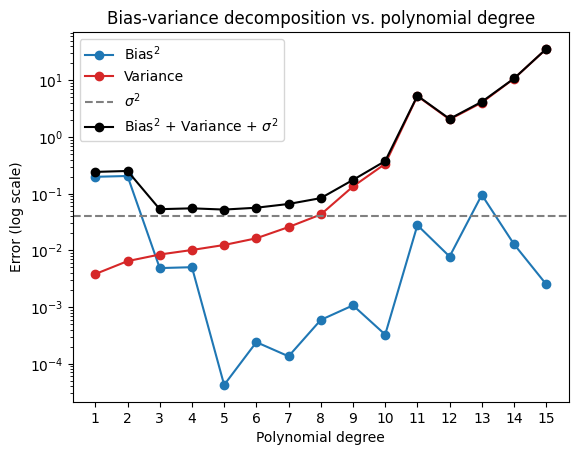

In [17]:
bias_squared_array = np.array(bias_squared_list)
variance_array = np.array(variance_list)
total_error = bias_squared_array + variance_array + NOISE_STD ** 2

plt.semilogy(degrees, bias_squared_array, "o-", color="tab:blue", label=r"Bias$^2$")
plt.semilogy(degrees, variance_array, "o-", color="tab:red", label="Variance")
plt.axhline(NOISE_STD ** 2, color="gray", linestyle="--", label=r"$\sigma^2$")
plt.semilogy(degrees, total_error, "o-", color="black", label=r"Bias$^2$ + Variance + $\sigma^2$")
plt.title("Bias-variance decomposition vs. polynomial degree")
plt.xlabel("Polynomial degree")
plt.xticks(degrees)
plt.ylabel("Error (log scale)")
plt.legend()
plt.show()

**Figure 8: Bias-variance decomposition estimated from 200 simulated training sets.** For every degree, we fitted 200 models on the same $x$ values with new noise and measured the squared bias, the variance and their sum with the noise level $\sigma^2 = 0.04$ (black line), averaged over the whole interval $[0, 1]$. The black line has the same U shape as the test error in Figure 6, which confirms the decomposition from Section 7.1:

- **Degrees 1–2 (underfitting):** the error is dominated by the squared bias (about $0.20$). The models are too simple to follow the sine, and more data or less noise would not help.
- **Degrees 3–8 (good fit):** the squared bias drops sharply at degree 3, while the variance is still small. The total error is close to the noise floor $\sigma^2$ and is lowest at degree 5 ($0.052$), although degrees 3 to 6 are almost equal.
- **Degrees 9–15 (overfitting):** the variance grows from $0.13$ to about $36$ and dominates the total error, so the black and red lines almost overlap. The models follow the noise, and each new training set gives a very different curve.

The best degree here (5) is different from the one in Figure 6 (7), because there the test error was measured on only 9 points from a single dataset, while here it is averaged over 200 datasets. A single small test set is therefore not a reliable way to choose the model complexity, which motivates cross-validation in Section 9. The jumps of the squared bias after degree 10 are artifacts of the simulation and not real bias: the average model $\bar{f}$ is estimated from only 200 models, so when the variance is large, this estimate is noisy too, and at these degrees `np.linalg.solve` also loses precision because $X^TX$ is almost singular (Section 6).

## 8. Regularization: Ridge and Lasso

Sections 6 and 7 showed that complex models overfit because their weights become very large and their variance explodes. Instead of limiting the degree, **regularization** keeps the complex model but adds a penalty on the size of the weights to the loss function. The model then has to balance two goals: fit the training data and keep the weights small.

### 8.1. Ridge regression (L2)

**The loss function.** Ridge regression [8] adds the squared L2 norm of the weights to the sum of squared errors:

$$ L(\mathbf{w}) = \lVert \mathbf{y} - X\mathbf{w} \rVert^2 + \lambda \lVert \mathbf{w} \rVert_2^2, \qquad \lVert \mathbf{w} \rVert_2^2 = \sum_{j} w_j^2 $$

The first term wants the curve to pass close to the training points, and the second term wants the weights to be close to zero. The **regularization strength** $\lambda \geq 0$ controls which of the two is more important:

- For $\lambda = 0$, the penalty disappears and we get ordinary least squares from Section 4.
- As $\lambda$ grows, the weights shrink towards zero and the curve becomes smoother, so the variance decreases.
- For a very large $\lambda$, all weights are almost zero, so $\hat{y} \approx 0$ everywhere and the model underfits.

So $\lambda$ moves the model between overfitting and underfitting, in a similar way as the degree did in Section 6, but continuously. We use the sum of squared errors instead of the mean (without the factor $\frac{1}{n}$ from Section 4.1), so that $\lambda$ has the same meaning as the parameter `alpha` in scikit-learn [2]. This does not change the minimum, only the scale of $\lambda$.

**Deriving the solution.** The derivation is the same as for the normal equation in Section 4.2, with one extra term. The gradient of the penalty is $\nabla_{\mathbf{w}}\big(\lambda\,\mathbf{w}^T\mathbf{w}\big) = 2\lambda\mathbf{w}$, the vector version of $(\lambda w^2)' = 2\lambda w$ [5]. Setting the gradient of the loss to zero gives:

$$ \nabla L(\mathbf{w}) = -2X^T\mathbf{y} + 2X^TX\mathbf{w} + 2\lambda\mathbf{w} = \mathbf{0} $$

Dividing by 2 and writing $\mathbf{w} = I\mathbf{w}$, where $I$ is the identity matrix, we get:

$$ (X^TX + \lambda I)\,\mathbf{w} = X^T\mathbf{y} \qquad \Longrightarrow \qquad \mathbf{w} = (X^TX + \lambda I)^{-1}X^T\mathbf{y} $$

The only difference from ordinary least squares is that $\lambda$ is added to the diagonal of $X^TX$. For $\lambda = 0$, we get back the normal equation.

**Why the matrix is always invertible.** A square matrix $A$ has no inverse exactly when there is a vector $\mathbf{v} \neq \mathbf{0}$ with $A\mathbf{v} = \mathbf{0}$. For any $\mathbf{v} \neq \mathbf{0}$ and $\lambda > 0$:

$$ \mathbf{v}^T(X^TX + \lambda I)\,\mathbf{v} = \mathbf{v}^TX^TX\mathbf{v} + \lambda\,\mathbf{v}^T\mathbf{v} = \underbrace{\lVert X\mathbf{v} \rVert^2}_{\geq\, 0} + \underbrace{\lambda \lVert \mathbf{v} \rVert^2}_{>\, 0} > 0 $$

If $(X^TX + \lambda I)\mathbf{v}$ were $\mathbf{0}$, the left side would be $0$, so this can never happen. Therefore $X^TX + \lambda I$ is **always invertible** for $\lambda > 0$, even when $X^TX$ itself is singular or almost singular. For example, the matrix $\begin{pmatrix} 1 & 1 \ 1 & 1 \end{pmatrix}$ has determinant $0$, but after adding $\lambda = 0.1$ to the diagonal, the determinant becomes $1.1^2 - 1 = 0.21 \neq 0$. This solves the numerical problem from Section 6, where $X^TX$ was almost singular for high degrees and `np.linalg.solve` lost precision.

In `fit_ridge_regression`, we solve this system with `np.linalg.solve`, as in Section 4. Note that we also penalize the intercept $w_0$, because it is a column of our design matrix like all the others. Below, we check that our implementation gives the same weights as linear regression for $\lambda = 0$ and the same weights as scikit-learn's `Ridge` for $\lambda > 0$.

In [18]:
def fit_ridge_regression(X, y, regularization_strength):
    """
    Finds the weights of Ridge regression using its closed-form solution
    """
    xtx = X.T @ X
    xty = X.T @ y
    identity = np.eye(xtx.shape[0])
    return np.linalg.solve(xtx + regularization_strength * identity, xty)

In [19]:
degree = 9
X_train_poly = polynomial_features(x_train, degree)

# Check 1: with lambda = 0, Ridge must give the same weights as linear regression
w_ridge_zero = fit_ridge_regression(X_train_poly, y_train, 0)
w_linear = fit_linear_regression(X_train_poly, y_train)
print("lambda = 0 same as linear regression?", np.allclose(w_ridge_zero, w_linear))

# Check 2: compare with scikit-learn's Ridge
regularization_strength = 0.001
w_ridge = fit_ridge_regression(X_train_poly, y_train, regularization_strength)
sk_ridge = Ridge(alpha=regularization_strength, fit_intercept=False)
sk_ridge.fit(X_train_poly, y_train)
print("Same weights as sklearn?", np.allclose(w_ridge, sk_ridge.coef_))

lambda = 0 same as linear regression? True
Same weights as sklearn? True


### 8.2. The effect of $\lambda$

Section 8.1 showed that $\lambda$ controls the balance between fitting the training data and keeping the weights small. Here we study this effect on the most overfitted model from Section 6, the polynomial of degree 15. First, we fit Ridge regression with four values of $\lambda$ and compare the fitted curves (Figure 9). Then we fit it for 100 values of $\lambda$ and follow how each weight changes as $\lambda$ grows. These curves are called **coefficient paths** (Figure 10). For comparison, Figure 11 shows the coefficient paths of Lasso, which uses the penalty $\lambda \sum_j |w_j|$ instead of $\lambda \sum_j w_j^2$. The theory behind Lasso is explained in Section 8.3.

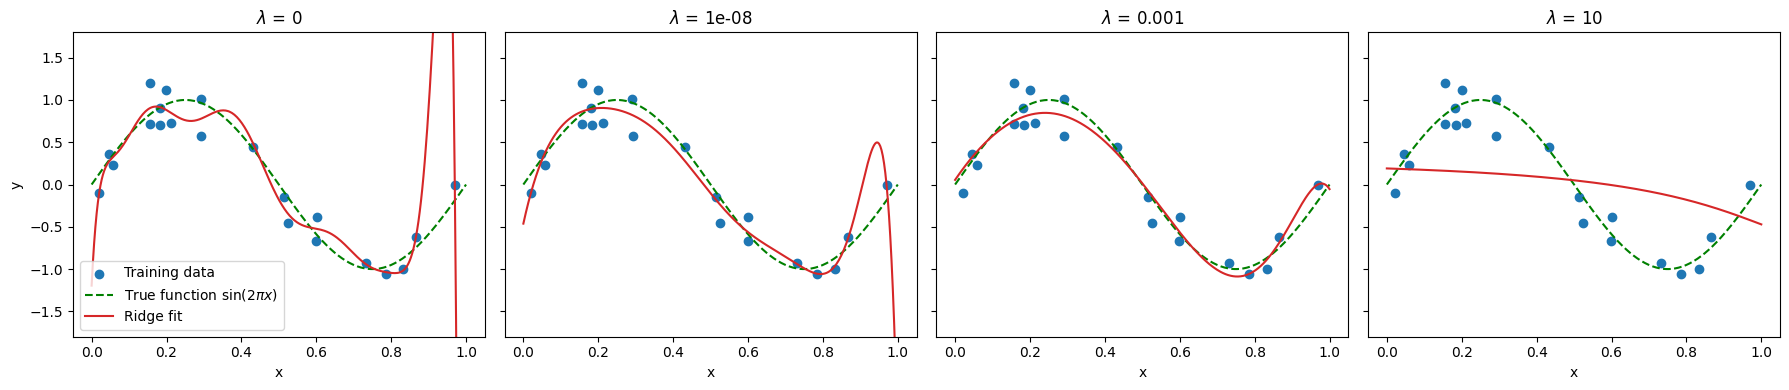

In [20]:
degree = 15
regularization_strengths = [0, 1e-8, 1e-3, 10]

X_train_poly = polynomial_features(x_train, degree)
X_plot_poly = polynomial_features(x_plot, degree)

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

for ax, regularization_strength in zip(axes, regularization_strengths):
    # 1. Fit Ridge with this lambda and predict on x_plot
    w_ridge = fit_ridge_regression(X_train_poly, y_train, regularization_strength)
    y_plot_ridge = predict(X_plot_poly, w_ridge)

    # 2. Plot (same as Figure 5)
    ax.scatter(x_train, y_train, color="tab:blue", label="Training data")
    ax.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
    ax.plot(x_plot, y_plot_ridge, color="tab:red", label="Ridge fit")
    ax.set_title(f"$\\lambda$ = {regularization_strength:g}")
    ax.set_xlabel("x")
    ax.set_ylim(-1.8, 1.8)

axes[0].set_ylabel("y")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Figure 9: Ridge regression with a polynomial of degree 15 for four values of $\lambda$.** The degree is the same in all panels, and only the regularization strength changes:

- **$\lambda = 0$:** ordinary least squares, the same overfitted model as in Figure 5. The largest weight is about $5.8 \times 10^6$, the curve oscillates between the training points and drops far below the plot near $x = 1$ (test MSE $1.82$).
- **$\lambda = 10^{-8}$:** even a tiny penalty shrinks the largest weight to about $490$ and reduces the test MSE to $0.080$. The curve is much calmer, but it still bends near the right end, where there are few training points and the variance is highest (Section 7.2).
- **$\lambda = 10^{-3}$:** the curve is smooth and close to the true function, and the test MSE is $0.024$. This is lower than the best unregularized polynomial in Figure 6 ($0.037$ at degree 7), although the model still has degree 15.
- **$\lambda = 10$:** the penalty dominates, all weights are close to zero (the largest is about $0.19$), and the curve is almost flat. The model underfits, and the test MSE grows to $0.45$.

As $\lambda$ grows, the model moves from overfitting to underfitting, in the same way as when we decreased the degree in Figure 5. This shows that regularization lets us keep a flexible model and control its complexity with a single continuous parameter. The best value of $\lambda$ cannot be read from the training error, which only grows with $\lambda$, so we choose it with cross-validation in Section 9.

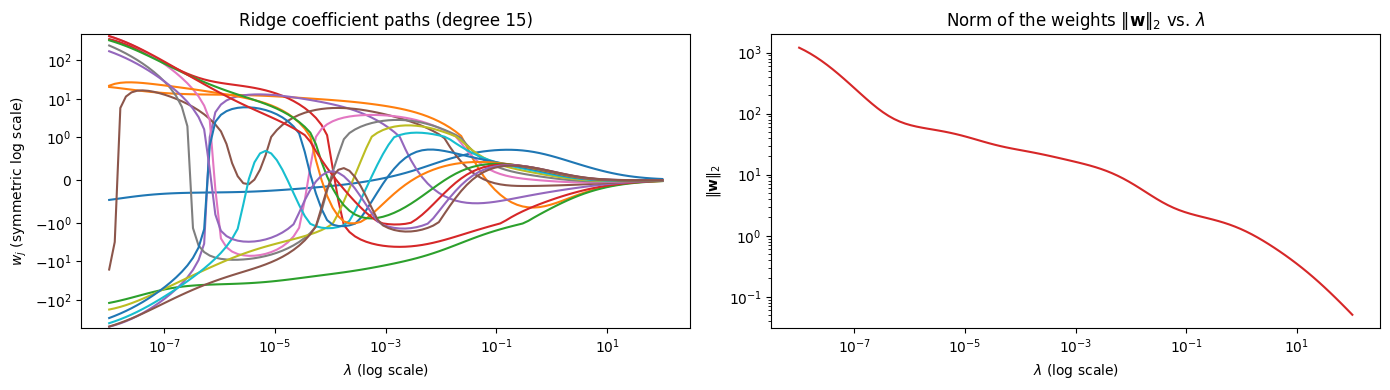

In [21]:
degree = 15
X_train_poly = polynomial_features(x_train, degree)

# 100 values of lambda between 10^-8 and 10^2, evenly spaced on a log scale
regularization_strengths = np.logspace(-8, 2, 100)

# Fit Ridge for every lambda and save the weights
ridge_weights = []
for regularization_strength in regularization_strengths:
    w_ridge = fit_ridge_regression(X_train_poly, y_train, regularization_strength)
    ridge_weights.append(w_ridge)
ridge_weights = np.array(ridge_weights)  # shape: (100, 16)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: one line per weight
for j in range(degree + 1):
    axes[0].plot(regularization_strengths, ridge_weights[:, j], label=f"$w_{j}$")
axes[0].set_xscale("log")
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_title("Ridge coefficient paths (degree 15)")
axes[0].set_xlabel(r"$\lambda$ (log scale)")
axes[0].set_ylabel(r"$w_j$ (symmetric log scale)")

# Right: the size of the whole weight vector
weight_norms = np.linalg.norm(ridge_weights, axis=1)
axes[1].loglog(regularization_strengths, weight_norms, color="tab:red")
axes[1].set_title(r"Norm of the weights $\|\mathbf{w}\|_2$ vs. $\lambda$")
axes[1].set_xlabel(r"$\lambda$ (log scale)")
axes[1].set_ylabel(r"$\|\mathbf{w}\|_2$")

plt.tight_layout()
plt.show()

**Figure 10: Ridge coefficient paths for a polynomial of degree 15.** We fitted Ridge regression for 100 values of $\lambda$ between $10^{-8}$ and $10^{2}$. The left panel shows how each of the 16 weights changes with $\lambda$ (one line per weight), and the right panel shows the size of the whole weight vector $\lVert \mathbf{w} \rVert_2$. The left end of both panels corresponds to the overfitted model in Figure 9 and the right end to the underfitted one.

- **Small $\lambda$:** the weights are large (up to about $490$) and have opposite signs, so they partly cancel each other. This is how the overfitted polynomial follows the noise in the training data.
- **Growing $\lambda$:** the individual weights do not change monotonically. Some of them change sign several times, because the columns $x^k$ of the design matrix are very similar and the weights trade off against each other. However, the norm $\lVert \mathbf{w} \rVert_2$ decreases at every step, from about $1200$ to about $0.05$. Ridge always shrinks the weight vector as a whole.
- **Large $\lambda$:** all lines converge to zero, which corresponds to the almost flat curve in Figure 9.

None of the weights becomes exactly zero for any $\lambda$: Ridge makes the weights small, but it keeps all features in the model. This is the main difference from Lasso (Section 8.3), which sets some weights to exactly zero.

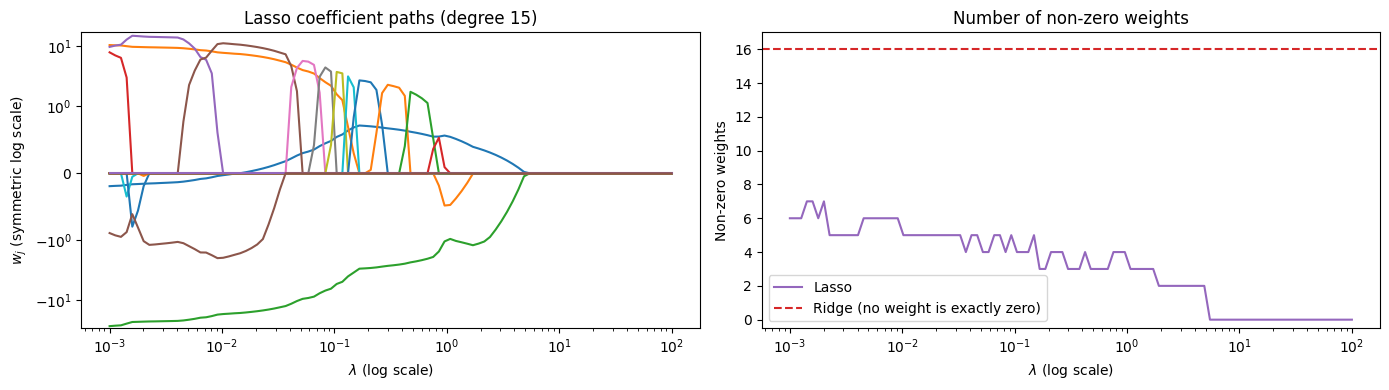

In [22]:
degree = 15
X_train_poly = polynomial_features(x_train, degree)
n = len(x_train)

# 100 values of lambda between 10^-3 and 10^2
regularization_strengths = np.logspace(-3, 2, 100)

# Fit Lasso for every lambda and save the weights.
# scikit-learn minimizes (1 / (2n)) * ||y - Xw||^2 + alpha * ||w||_1,
# so alpha = lambda / (2n) gives the same minimum as our loss ||y - Xw||^2 + lambda * ||w||_1
lasso_weights = []
for regularization_strength in regularization_strengths:
    lasso_model = Lasso(alpha=regularization_strength / (2 * n), fit_intercept=False, max_iter=300000)
    lasso_model.fit(X_train_poly, y_train)
    lasso_weights.append(lasso_model.coef_)
lasso_weights = np.array(lasso_weights)  # shape: (100, 16)

# Number of weights that are exactly zero is the number of features Lasso removed
nonzero_weights = np.sum(lasso_weights != 0, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: one line per weight
for j in range(degree + 1):
    axes[0].plot(regularization_strengths, lasso_weights[:, j])
axes[0].set_xscale("log")
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_title("Lasso coefficient paths (degree 15)")
axes[0].set_xlabel(r"$\lambda$ (log scale)")
axes[0].set_ylabel(r"$w_j$ (symmetric log scale)")

# Right: how many weights are not zero, compared with Ridge
axes[1].semilogx(regularization_strengths, nonzero_weights, color="tab:purple", label="Lasso")
axes[1].axhline(degree + 1, color="tab:red", linestyle="--", label="Ridge (no weight is exactly zero)")
axes[1].set_title("Number of non-zero weights")
axes[1].set_xlabel(r"$\lambda$ (log scale)")
axes[1].set_ylabel("Non-zero weights")
axes[1].set_ylim(-0.5, degree + 2)
axes[1].legend()

plt.tight_layout()
plt.show()

**Figure 11: Lasso coefficient paths for a polynomial of degree 15, compared with Ridge.** Lasso has no closed-form solution, so we fit it with scikit-learn's `Lasso` [2] for 100 values of $\lambda$ between $10^{-3}$ and $10^{2}$. scikit-learn minimizes $\frac{1}{2n}\lVert \mathbf{y} - X\mathbf{w} \rVert^2 + \alpha \lVert \mathbf{w} \rVert_1$, so we set $\alpha = \frac{\lambda}{2n}$ to get the same minimum as our loss $\lVert \mathbf{y} - X\mathbf{w} \rVert^2 + \lambda \lVert \mathbf{w} \rVert_1$. The left panel shows each of the 16 weights, and the right panel shows how many of them are not exactly zero.

- **Exact zeros:** unlike Ridge in Figure 10, many Lasso paths lie exactly on the zero line. Even for the smallest $\lambda = 10^{-3}$, only 6 of the 16 weights are non-zero, and the other features are removed from the model completely.
- **Fewer features as $\lambda$ grows:** the number of non-zero weights generally decreases with $\lambda$, although a weight can sometimes enter the model again when another one leaves it. From about $\lambda \approx 5.3$, all weights are exactly zero and the model predicts $\hat{y} = 0$ everywhere. For Ridge, all 16 weights stay non-zero for every $\lambda$ (dashed line).
- **Accuracy:** the lowest test MSE on this grid is $0.026$ at $\lambda \approx 0.009$, where the model uses only 6 weights ($w_0, w_1, w_2, w_4, w_5, w_{15}$). This is close to the best Ridge model in Figure 9 ($0.024$), but the Lasso model is much simpler.

Ridge shrinks all weights but keeps them, while Lasso shrinks some weights and sets the others to exactly zero. Lasso therefore also performs **feature selection**. Section 8.3 explains why the L1 penalty leads to exact zeros.

### 8.3. Lasso regression (L1)

**The loss function.** Lasso regression [9] uses the L1 norm of the weights instead of the squared L2 norm:

$$ L(\mathbf{w}) = \lVert \mathbf{y} - X\mathbf{w} \rVert^2 + \lambda \lVert \mathbf{w} \rVert_1, \qquad \lVert \mathbf{w} \rVert_1 = \sum_{j} |w_j| $$

As with Ridge, $\lambda = 0$ gives ordinary least squares, and a larger $\lambda$ pushes the weights towards zero. The difference is in *how* the weights are pushed.

**Why there is no closed-form solution.** For Ridge, we set the gradient to zero and solved a linear system. This works because $w^2$ is smooth and its derivative $2w$ exists everywhere. The function $|w|$ has a sharp corner at $w = 0$: its slope is $-1$ on the left and $+1$ on the right, so it has no derivative at zero. The condition "gradient $= 0$" cannot be written as one linear system, and there is no formula like $(X^TX + \lambda I)^{-1}X^T\mathbf{y}$. Instead, the minimum is found iteratively. scikit-learn's `Lasso` uses coordinate descent, which updates one weight at a time while keeping the others fixed [2].

**Why Lasso sets weights to exactly zero.** The difference becomes clear with a single weight $w$ and a single data point with value $a$ (the model is $\hat{y} = w$). For Ridge, setting the derivative of $(a - w)^2 + \lambda w^2$ to zero gives:

$$ w_{\text{Ridge}} = \frac{a}{1 + \lambda} $$

For Lasso, we minimize $(a - w)^2 + \lambda |w|$ separately for $w > 0$ and $w < 0$. For $w > 0$, the derivative $-2(a - w) + \lambda = 0$ gives $w = a - \frac{\lambda}{2}$, which is valid only if $a > \frac{\lambda}{2}$. The case $w < 0$ is symmetric. If $|a| \leq \frac{\lambda}{2}$, neither case is valid and the minimum is at the corner $w = 0$. Together:

$$ w_{\text{Lasso}} = \begin{cases} a - \frac{\lambda}{2} & \text{if } a > \frac{\lambda}{2} \ 0 & \text{if } |a| \leq \frac{\lambda}{2} \ a + \frac{\lambda}{2} & \text{if } a < -\frac{\lambda}{2} \end{cases} $$

This operation is called **soft thresholding**, and coordinate descent applies a similar step to each weight. For $a = 1$:

| $\lambda$ | $w_{\text{Ridge}} = \frac{1}{1 + \lambda}$ | $w_{\text{Lasso}}$ |
|---|---|---|
| $0$ | $1$ | $1$ |
| $1$ | $0.5$ | $0.5$ |
| $2$ | $0.33$ | $0$ |
| $4$ | $0.2$ | $0$ |
| $100$ | $0.0099$ | $0$ |

Ridge **divides** the weight by $1 + \lambda$, so it becomes smaller but never exactly zero. Lasso **subtracts** a constant $\frac{\lambda}{2}$, so the weight reaches zero and stays there. The reason is in the derivatives of the penalties: the pull of the Ridge penalty $2\lambda w$ becomes weaker as $w$ approaches zero, while the pull of the Lasso penalty has the constant size $\lambda$. If the data supports a weight less strongly than this constant pull, the weight is set to exactly zero.

**Feature selection.** A weight of exactly zero means that the corresponding feature, for example $x^7$, is not used by the model at all. Lasso therefore selects the features automatically. This is what we saw in Figure 11: the best Lasso model uses only 6 of the 16 features and reaches almost the same test error as Ridge, which keeps all 16. This makes Lasso models simpler and easier to interpret, which will be useful for the real-world dataset in Section 10.

### 8.4. Geometric interpretation

Both penalties can also be written as a constraint: instead of adding $\lambda$ times the penalty to the loss, we minimize the squared error only over the weights inside a fixed "budget" $t$:

$$ \min_{\mathbf{w}} \lVert \mathbf{y} - X\mathbf{w} \rVert^2 \quad \text{subject to} \quad \lVert \mathbf{w} \rVert_2^2 \leq t \;\; \text{(Ridge)} \qquad \text{or} \qquad \lVert \mathbf{w} \rVert_1 \leq t \;\; \text{(Lasso)} $$

For every $\lambda > 0$, there is a budget $t$ for which both formulations have the same solution, and a larger $\lambda$ corresponds to a smaller $t$ [9]. With two weights $w_1$ and $w_2$, the allowed region of Ridge, $w_1^2 + w_2^2 \leq t$, is a **circle**, and the allowed region of Lasso, $|w_1| + |w_2| \leq t$, is a **diamond** with its corners on the axes. The contours of the squared error are ellipses around the unregularized solution. The regularized solution is the point where the smallest ellipse first touches the allowed region.

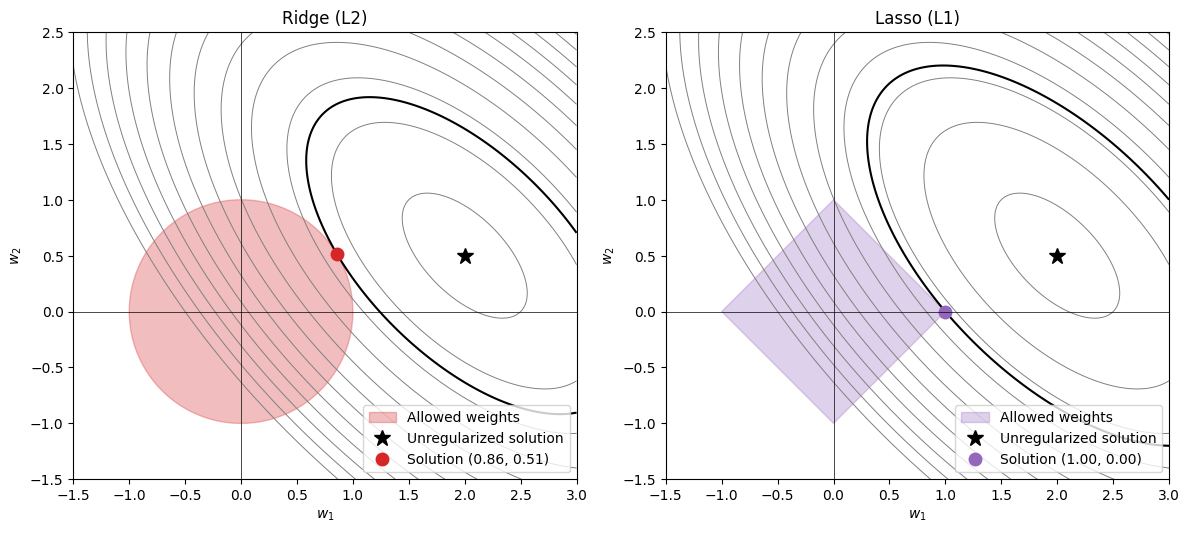

In [23]:
# An illustrative loss with two weights: L(w) = (w - w_ols)^T A (w - w_ols)
# Its contours are ellipses around the unregularized solution w_ols
w_ols = np.array([2.0, 0.5])
A = np.array([[1.0, 0.6],
              [0.6, 1.0]])

def loss(w1, w2):
    """
    Returns the illustrative loss for the weights w1 and w2
    """
    d1, d2 = w1 - w_ols[0], w2 - w_ols[1]
    return A[0, 0] * d1 ** 2 + 2 * A[0, 1] * d1 * d2 + A[1, 1] * d2 ** 2

# Boundaries of the two constraint regions with budget t = 1
angles = np.linspace(0, 2 * np.pi, 2000)
circle = np.column_stack([np.cos(angles), np.sin(angles)])
diamond = np.column_stack([np.cos(angles), np.sin(angles)])
diamond = diamond / np.abs(diamond).sum(axis=1, keepdims=True)

w1_grid, w2_grid = np.meshgrid(np.linspace(-1.5, 3, 400), np.linspace(-1.5, 2.5, 400))
loss_grid = loss(w1_grid, w2_grid)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, boundary, name, color in zip(axes, [circle, diamond], ["Ridge (L2)", "Lasso (L1)"], ["tab:red", "tab:purple"]):
    # The solution is the point of the region with the smallest loss
    boundary_loss = loss(boundary[:, 0], boundary[:, 1])
    w_best = boundary[np.argmin(boundary_loss)]

    ax.contour(w1_grid, w2_grid, loss_grid, levels=np.linspace(0.2, 8, 12), colors="gray", linewidths=0.7)
    ax.contour(w1_grid, w2_grid, loss_grid, levels=[boundary_loss.min()], colors="black", linewidths=1.5)
    ax.fill(boundary[:, 0], boundary[:, 1], color=color, alpha=0.3, label="Allowed weights")
    ax.plot(*w_ols, "k*", markersize=12, label="Unregularized solution")
    ax.plot(*w_best, "o", color=color, markersize=9, label=f"Solution ({w_best[0]:.2f}, {w_best[1]:.2f})")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("$w_1$")
    ax.set_ylabel("$w_2$")
    ax.set_aspect("equal")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

**Figure 12: Geometric interpretation of Ridge and Lasso with two weights.** The gray ellipses are contours of an illustrative squared-error loss, the star is its unregularized minimum, and the colored regions are the weights allowed by the budget $t = 1$. The black ellipse is the smallest contour that touches the region, and the dot is the regularized solution, found as the point of the region's border with the lowest loss.

- **Ridge (left):** the circle has no corners, so the ellipse touches it at a point where both weights are non-zero, here $(0.86, 0.51)$. Both weights are shrunk, but neither becomes zero.
- **Lasso (right):** the diamond has sharp corners on the axes, and the ellipse touches it first at the corner $(1, 0)$. The weight $w_2$ is exactly zero.

The corners of the diamond are the geometric version of the corner of $|w|$ at zero from Section 8.3. Lasso does not always produce zeros: if the unregularized solution lies in a different direction, the ellipse can touch an edge of the diamond instead of a corner. In higher dimensions, however, the L1 region has many corners and edges where some weights are zero, so this happens very often, as we saw with 10 of the 16 weights in Figure 11.

## 9. Model Selection with Cross-Validation
> TODO: Explain k-fold cross-validation. Why is it better than a single train/test split?

In [24]:
def k_fold_cross_validation(X, y, fit_function, k = 5):
    """
    Splits the data into k folds, trains on k - 1 of them and tests on the remaining one.
    Returns the average test error
    """
    # Write your code here
    pass

> TODO: Use cross-validation to choose the best polynomial degree and the best $\lambda$.

## 10. Real-World Application
> TODO: Apply the methods to a real dataset (e.g. `sklearn.datasets.load_diabetes`). Compare plain linear regression, Ridge and Lasso. Which features does Lasso keep?

## 11. Discussion and Limitations
> TODO: What worked? What did not? What are the limitations of the assumptions from 1.4?

## 12. Conclusion and Next Steps
> TODO: Answer the question from the problem formulation. What could be explored next (e.g. regularization in neural networks, dropout, early stopping)?

## 13. References

1. Multimatics, "Detect and Prevent Overfitting and Underfitting in Machine Learning," *Multimatics Insight*, Sep. 29, 2023. [Online]. Available: https://multimatics.co.id/insight/sep/detect-and-prevent-overfitting-and-underfitting-in-machine-learning (accessed Oct. 23, 2026).

2. F. Pedregosa et al., "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

3. B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression," *Annals of Statistics*, vol. 32, no. 2, pp. 407–499, 2004.

4. M. P. Deisenroth, A. A. Faisal and C. S. Ong, *Mathematics for Machine Learning*. Cambridge University Press, 2020, ch. 9. [Online]. Available: https://mml-book.github.io/

5. K. B. Petersen and M. S. Pedersen, *The Matrix Cookbook*. Technical University of Denmark, 2012.

6. S. Geman, E. Bienenstock and R. Doursat, "Neural Networks and the Bias/Variance Dilemma," *Neural Computation*, vol. 4, no. 1, pp. 1–58, 1992.

7. T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed. Springer, 2009, sec. 7.3. [Online]. Available: https://hastie.su.domains/ElemStatLearn/

8. A. E. Hoerl and R. W. Kennard, "Ridge Regression: Biased Estimation for Nonorthogonal Problems," *Technometrics*, vol. 12, no. 1, pp. 55–67, 1970.

9. R. Tibshirani, "Regression Shrinkage and Selection via the Lasso," *Journal of the Royal Statistical Society: Series B (Methodological)*, vol. 58, no. 1, pp. 267–288, 1996.